# Лабораторная №2. Классификация пассажиров Titanic

Цель — предсказать `Survived`: выжил пассажир (`1`) или нет (`0`). Использован [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset). Исходный CSV сохранён в `classification/data/titanic.csv`

Основная метрика — **F1-score** для класса `Survived = 1`

In [1]:
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay,
)

plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
pd.set_option("display.precision", 4)

data_path = Path("data/titanic.csv") if Path("data/titanic.csv").exists() else Path("classification/data/titanic.csv")
data = pd.read_csv(data_path)
print("Размер:", data.shape)
display(data.head())

Размер: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Первичный анализ

Проверяем типы, пропуски, дубликаты и баланс целевой переменной. `PassengerId`, `Name` и `Ticket` не используем: это идентификаторы, по которым модель может запоминать пассажиров, а не искать закономерности. `Cabin` пропускаем из-за большого числа пропусков и высокой детализации значений.

,тип,пропуски,доля пропусков
PassengerId,int64,0,0.0000
Survived,int64,0,0.0000
Pclass,int64,0,0.0000
Name,str,0,0.0000
Sex,str,0,0.0000
Age,float64,177,0.1987
SibSp,int64,0,0.0000
Parch,int64,0,0.0000
Ticket,str,0,0.0000
Fare,float64,0,0.0000


Полных дубликатов: 0


,count
Survived,
0,549
1,342


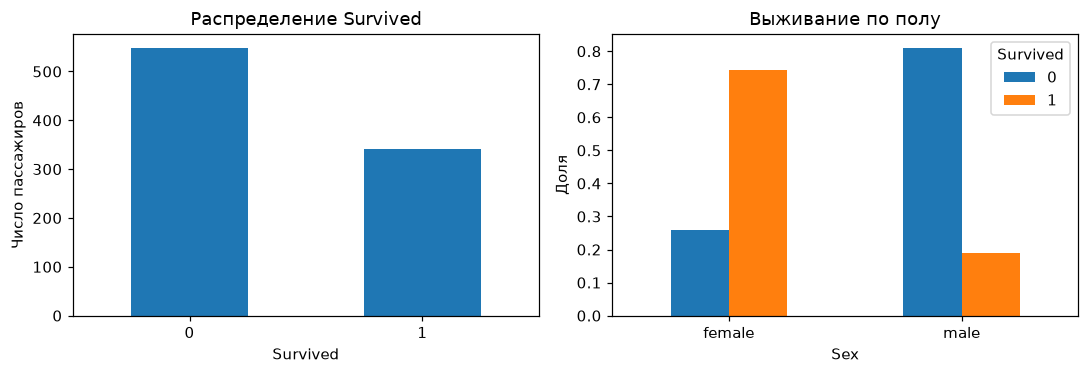

In [2]:
summary = pd.DataFrame({
    "тип": data.dtypes.astype(str),
    "пропуски": data.isna().sum(),
    "доля пропусков": data.isna().mean(),
})
display(summary)
print("Полных дубликатов:", data.duplicated().sum())
display(data["Survived"].value_counts().rename_axis("Survived").to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
data["Survived"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Распределение Survived", xlabel="Survived", ylabel="Число пассажиров")
pd.crosstab(data["Sex"], data["Survived"], normalize="index").plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Выживание по полу", xlabel="Sex", ylabel="Доля")
axes[1].legend(title="Survived")
plt.tight_layout()
plt.show()

**Вывод.** В `Age`, `Cabin` и `Embarked` есть пропуски. `Age` заполняем медианой. `Embarked` — самым частым значением
## 2. Подготовка и разбиение

Делим данные на train и test в пропорции 80/20 с `stratify=y`, чтобы в обеих частях сохранилось соотношение классов. Все заполнения пропусков, кодирование и масштабирование находятся внутри `Pipeline`, поэтому их параметры вычисляются только на train. Для SVM и KNN масштабирование числовых признаков важно

In [3]:
target = "Survived"
drop_columns = ["Survived", "PassengerId", "Name", "Ticket", "Cabin"]
X = data.drop(columns=drop_columns)
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2026
)
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
scaled_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

assert target not in X.columns
assert set(X_train.index).isdisjoint(X_test.index)
assert not set(["PassengerId", "Name", "Ticket", "Cabin"]) & set(X.columns)

Train: (712, 7) | Test: (179, 7)
Числовые признаки: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Категориальные признаки: ['Sex', 'Embarked']


## 3. Baseline и модели

Параметры пяти моделей выбираются по среднему F1 на пяти стратифицированных разбиениях **только train**. Обработка пропусков, кодирование и масштабирование заново обучаются внутри каждого фолда. `class_weight="balanced"` у дерева и леса увеличивает вес менее частого класса. Лучшую модель для подробного разбора тоже выбираем по CV, до просмотра test.

In [4]:
models = {
    "Baseline": Pipeline([
        ("prep", clone(tree_preprocessor)),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "Decision Tree": Pipeline([
        ("prep", clone(tree_preprocessor)),
        ("model", DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=3, class_weight="balanced", random_state=42
        )),
    ]),
    "Random Forest": Pipeline([
        ("prep", clone(tree_preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=300, max_depth=6, min_samples_leaf=3,
            max_features="sqrt", class_weight="balanced", random_state=42
        )),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", clone(tree_preprocessor)),
        ("model", GradientBoostingClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42
        )),
    ]),
    "SVM": Pipeline([
        ("prep", clone(scaled_preprocessor)),
        ("model", SVC(C=1, kernel="rbf", random_state=42)),
    ]),
    "KNN": Pipeline([
        ("prep", clone(scaled_preprocessor)),
        ("model", KNeighborsClassifier(n_neighbors=15, weights="distance")),
    ]),
}

# Сначала baseline, затем подбор моделей без доступа к test.
models["Baseline"].fit(X_train, y_train)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grids = {
    "Decision Tree": {
        "model__max_depth": [3, 4, 5], "model__min_samples_leaf": [3, 5, 10],
    },
    "Random Forest": {
        "model__max_depth": [5, 8, None], "model__min_samples_leaf": [2, 5],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200], "model__max_depth": [2, 3],
        "model__learning_rate": [0.05, 0.1],
    },
    "SVM": {"model__C": [0.5, 1, 3], "model__class_weight": [None, "balanced"]},
    "KNN": {"model__n_neighbors": [5, 9, 15, 21], "model__weights": ["uniform", "distance"]},
}
cv_scores = {}
for name, grid in grids.items():
    search = GridSearchCV(models[name], grid, scoring="f1", cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    cv_scores[name] = search.best_score_
    print(name, search.best_params_, "F1 CV:", round(search.best_score_, 4))

# Выбор лучшей модели закончен до финальной оценки.
best_name = max(cv_scores, key=cv_scores.get)
print("Лучшая модель по CV:", best_name)

# Финальная оценка: predict на test выполняется один раз для каждой модели.
predictions = {}
rows = []
for name, model in models.items():
    prediction = model.predict(X_test)
    predictions[name] = prediction
    rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction, zero_division=0),
        "F1 train": f1_score(y_train, model.predict(X_train), zero_division=0),
        "F1 CV": cv_scores.get(name, np.nan),
    })
results = pd.DataFrame(rows).set_index("Модель")
display(results)
print("F1 > 0.70:", results.index[results["F1"] > 0.70].tolist())

Decision Tree {'model__max_depth': 4, 'model__min_samples_leaf': 5} F1 CV: 0.7592
Random Forest {'model__max_depth': None, 'model__min_samples_leaf': 2} F1 CV: 0.7595
Gradient Boosting {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200} F1 CV: 0.7576
SVM {'model__C': 1, 'model__class_weight': 'balanced'} F1 CV: 0.7508
KNN {'model__n_neighbors': 21, 'model__weights': 'uniform'} F1 CV: 0.7414
Лучшая модель по CV: Random Forest


,Accuracy,Precision,Recall,F1,F1 train,F1 CV
Модель,,,,,,
Baseline,0.6145,0.0000,0.0000,0.0000,0.0000,NaN
Decision Tree,0.7709,0.6628,0.8261,0.7355,0.7803,0.7592
Random Forest,0.8380,0.8030,0.7681,0.7852,0.8881,0.7595
Gradient Boosting,0.8212,0.7846,0.7391,0.7612,0.9216,0.7576
SVM,0.8156,0.7812,0.7246,0.7519,0.7888,0.7508
KNN,0.8212,0.8033,0.7101,0.7538,0.7475,0.7414


F1 > 0.70: ['Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM', 'KNN']


**Вывод.** У дерева F1 train = 0.7803 и test = 0.7355: есть небольшой разрыв. У бустинга он сильнее (0.9216 против 0.7612), что указывает на переобучение. Лес имеет test F1 = 0.7852 и превосходит бустинг

## 4. Confusion matrix

Accuracy — доля верных прогнозов. Precision — доля действительно выживших среди предсказанных выживших. Recall — доля найденных выживших среди всех выживших. F1 — гармоническое среднее Precision и Recall. В матрицах строки — настоящий класс, столбцы — прогноз.


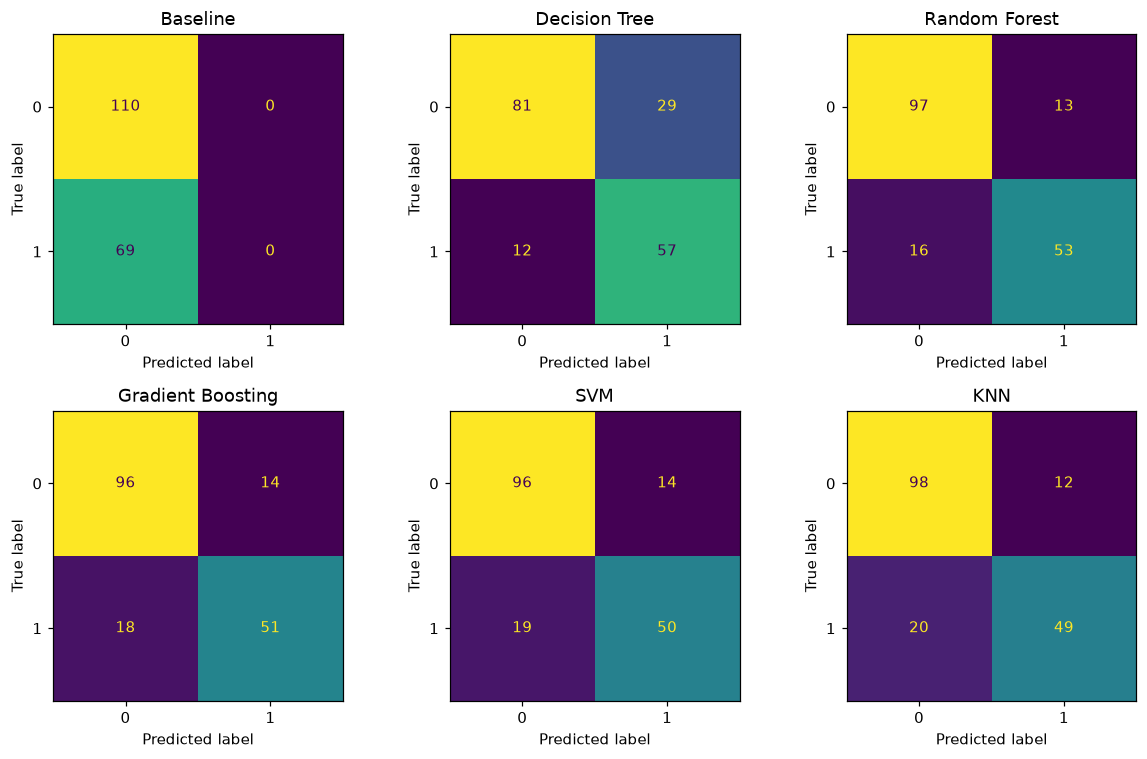

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, (name, prediction) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, prediction)).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 5. Важность признаков

Decision Tree топ-3: {'Sex_female': 0.5982, 'Fare': 0.1539, 'Age': 0.1285}
Random Forest топ-3: {'Fare': 0.234, 'Age': 0.1986, 'Sex_male': 0.1925}
Gradient Boosting топ-3: {'Sex_female': 0.3199, 'Fare': 0.2124, 'Age': 0.1814}


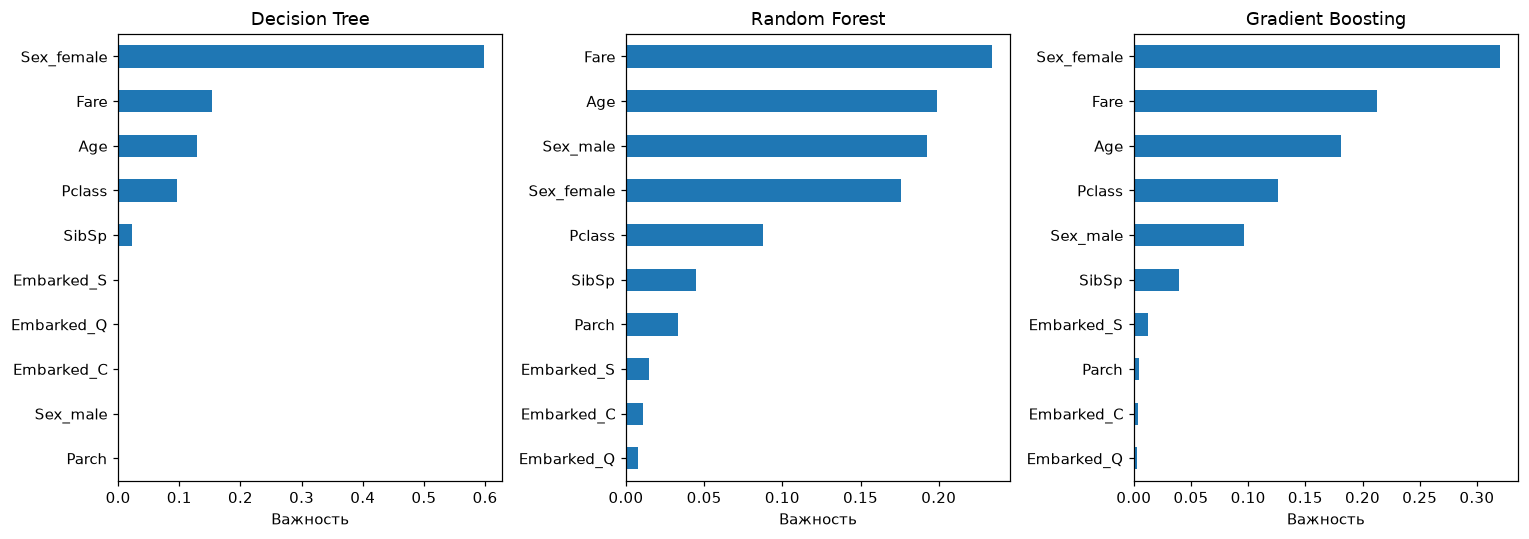

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, name in zip(axes, ["Decision Tree", "Random Forest", "Gradient Boosting"]):
    model = models[name]
    feature_names = model.named_steps["prep"].get_feature_names_out()
    importance = pd.Series(
        model.named_steps["model"].feature_importances_, index=feature_names
    ).sort_values().tail(10)
    importance.index = (importance.index.str.replace("num__", "", regex=False)
                                        .str.replace("cat__", "", regex=False))
    print(name, "топ-3:", importance.nlargest(3).round(4).to_dict())
    importance.plot.barh(ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Важность")
plt.tight_layout()
plt.show()

**Вывод по важностям.** У дерева лидируют пол, стоимость билета и возраст, у леса — стоимость, возраст и пол, у бустинга — пол, стоимость и возраст

## 6. Анализ ошибок лучшей модели

Для модели с лучшим средним F1 на CV подробнее рассматриваем FP, FN, группы пассажиров и примеры ошибок

In [7]:
best_prediction = predictions[best_name]
errors = data.loc[y_test.index, ["PassengerId", "Pclass", "Sex", "Age", "Fare", "Survived"]].copy()
errors["prediction"] = best_prediction
errors["correct"] = errors["Survived"] == errors["prediction"]

print("Лучшая модель:", best_name)
tn, fp, fn, tp = confusion_matrix(y_test, best_prediction).ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
display(pd.crosstab(errors["Sex"], errors["correct"], normalize="index").rename(columns={False: "ошибка", True: "верно"}))
display(pd.crosstab(errors["Pclass"], errors["correct"], normalize="index").rename(columns={False: "ошибка", True: "верно"}))

false_negative = errors[(errors["Survived"] == 1) & (errors["prediction"] == 0)]
false_positive = errors[(errors["Survived"] == 0) & (errors["prediction"] == 1)]
print("False Negative: модель не предсказала выживание")
display(false_negative.head(3))
print("False Positive: модель предсказала выживание ошибочно")
display(false_positive.head(3))

Лучшая модель: Random Forest
TN=97, FP=13, FN=16, TP=53


correct,ошибка,верно
Sex,,
female,0.1724,0.8276
male,0.1570,0.8430


correct,ошибка,верно
Pclass,,
1,0.1818,0.8182
2,0.0909,0.9091
3,0.1868,0.8132


False Negative: модель не предсказала выживание


,PassengerId,Pclass,Sex,Age,Fare,Survived,prediction,correct
400,401,3,male,39.0,7.9250,1,0,False
630,631,1,male,80.0,30.0000,1,0,False
569,570,3,male,32.0,7.8542,1,0,False


False Positive: модель предсказала выживание ошибочно


,PassengerId,Pclass,Sex,Age,Fare,Survived,prediction,correct
593,594,3,female,NaN,7.750,0,1,False
505,506,1,male,18.0,108.900,0,1,False
374,375,3,female,3.0,21.075,0,1,False


**Вывод по ошибкам.** У выбранного по CV леса FN = 16 и FP = 13: чаще модель пропускает выживших. Ошибки составляют 17.2% среди женщин и 15.7% среди мужчин. По классу билета: 18.2% в первом, 9.1% во втором и 18.7% в третьем
